<a href="https://colab.research.google.com/github/soumilijn-tech/AIML-LAB/blob/main/LAB_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Problem Statement: You have the processed Stroke Dataset. Now apply any five (05) Supervised Machine Learning Models to it, and also apply an ANN (Artificial Neural Network) as a Sixth model. Please show the following performance parameters: Precision, Recall, F1-Score, Accuracy, and AUC-ROC curve. Also show the Confusion Matrix of each model. Finally, evaluate the top 3 models for stroke risk prediction analysis and show the comparative results in the output.

In [1]:
from google.colab import files

uploaded = files.upload()

Saving stroke_processed_5k.csv to stroke_processed_5k.csv


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("stroke_processed_5k.csv")

print("Dataset Shape:", df.shape)

Dataset Shape: (5110, 11)


In [3]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


In [4]:
print(df.columns.tolist())

['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


In [5]:
if "index" in df.columns:
    df = df.drop("index", axis=1)

print(df.shape)

(5110, 11)


Check Missing Value

In [6]:
print(df.isnull().sum())

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


Target Distribution

In [7]:
print(df["stroke"].value_counts())

stroke
0    4861
1     249
Name: count, dtype: int64


Create X and Y

In [8]:
X = df.drop("stroke", axis=1)
y = df["stroke"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5110, 10)
y shape: (5110,)


Train/Test Split

In [9]:
from sklearn.model_selection import train_test_split

# 70% Training + 30% Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

In [10]:
# 20% Testing + 10% Validation
X_test, X_val, y_test, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=1/3,
    stratify=y_temp,
    random_state=42
)

In [11]:
print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("Validation:", X_val.shape)

Training: (3577, 10)
Testing: (1022, 10)
Validation: (511, 10)


In [12]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
stroke
0    3403
1     174
Name: count, dtype: int64

After SMOTE:
stroke
0    3403
1    3403
Name: count, dtype: int64


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

Logistic Regression

In [14]:
lr_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(
    X_train_smote,
    y_train_smote
)

lr_pred = lr_model.predict(X_test)
lr_prob = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression completed!")

Logistic Regression completed!


Decision Tree

In [15]:
dt_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

dt_model.fit(
    X_train_smote,
    y_train_smote
)

dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree completed!")

Decision Tree completed!


Random Forest

In [16]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_smote,
    y_train_smote
)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest completed!")

Random Forest completed!


SVM

In [17]:
svm_model = SVC(
    kernel="rbf",
    probability=True,
    class_weight="balanced",
    random_state=42
)

svm_model.fit(
    X_train_smote,
    y_train_smote
)

svm_pred = svm_model.predict(X_test)
svm_prob = svm_model.predict_proba(X_test)[:, 1]

print("SVM completed!")

SVM completed!


KNN

In [18]:
knn_model = KNeighborsClassifier(
    n_neighbors=7,
    weights="distance"
)

knn_model.fit(
    X_train_smote,
    y_train_smote
)

knn_pred = knn_model.predict(X_test)
knn_prob = knn_model.predict_proba(X_test)[:, 1]

print("KNN completed!")

KNN completed!


ANN

In [19]:
ann_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    alpha=0.0005,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    random_state=42
)

ann_model.fit(
    X_train_smote,
    y_train_smote
)

ann_pred = ann_model.predict(X_test)
ann_prob = ann_model.predict_proba(X_test)[:, 1]

print("ANN completed!")

ANN completed!


Metrics Import

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

Evaluation Function

In [21]:
def evaluate_model(name, y_true, y_pred, y_prob):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    return {
        "Model": name,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Accuracy": accuracy,
        "AUC-ROC": auc
    }

Evalute all 6 model

In [22]:
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        lr_pred,
        lr_prob
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        dt_pred,
        dt_prob
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred,
        rf_prob
    )
)

results.append(
    evaluate_model(
        "SVM",
        y_test,
        svm_pred,
        svm_prob
    )
)

results.append(
    evaluate_model(
        "KNN",
        y_test,
        knn_pred,
        knn_prob
    )
)

results.append(
    evaluate_model(
        "ANN",
        y_test,
        ann_pred,
        ann_prob
    )
)

In [23]:
results_df = pd.DataFrame(results)

results_df

,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.129964,0.72,0.220183,0.750489,0.819979
1,Decision Tree,0.112540,0.70,0.193906,0.715264,0.787572
2,Random Forest,0.115789,0.22,0.151724,0.879648,0.796605
3,SVM,0.099631,0.54,0.168224,0.738748,0.766698
4,KNN,0.087500,0.42,0.144828,0.757339,0.707757
5,ANN,0.105505,0.46,0.171642,0.782779,0.752325


In [24]:
results_df.style.format({
    "Precision": "{:.3f}",
    "Recall": "{:.3f}",
    "F1-Score": "{:.3f}",
    "Accuracy": "{:.3f}",
    "AUC-ROC": "{:.3f}"
})

,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.130,0.720,0.220,0.750,0.820
1,Decision Tree,0.113,0.700,0.194,0.715,0.788
2,Random Forest,0.116,0.220,0.152,0.880,0.797
3,SVM,0.100,0.540,0.168,0.739,0.767
4,KNN,0.087,0.420,0.145,0.757,0.708
5,ANN,0.106,0.460,0.172,0.783,0.752


Ranking based AUC

In [25]:
results_ranked = results_df.sort_values(
    by="AUC-ROC",
    ascending=False
).reset_index(drop=True)

results_ranked

,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.129964,0.72,0.220183,0.750489,0.819979
1,Random Forest,0.115789,0.22,0.151724,0.879648,0.796605
2,Decision Tree,0.112540,0.70,0.193906,0.715264,0.787572
3,SVM,0.099631,0.54,0.168224,0.738748,0.766698
4,ANN,0.105505,0.46,0.171642,0.782779,0.752325
5,KNN,0.087500,0.42,0.144828,0.757339,0.707757


In [26]:
top3 = results_ranked.head(3)

print("Top 3 Models:")
display(top3)

Top 3 Models:


,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.129964,0.72,0.220183,0.750489,0.819979
1,Random Forest,0.115789,0.22,0.151724,0.879648,0.796605
2,Decision Tree,0.112540,0.70,0.193906,0.715264,0.787572


In [27]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
predictions = {
    "Logistic Regression": lr_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "SVM": svm_pred,
    "KNN": knn_pred,
    "ANN": ann_pred
}

create 6 confusion Matrix

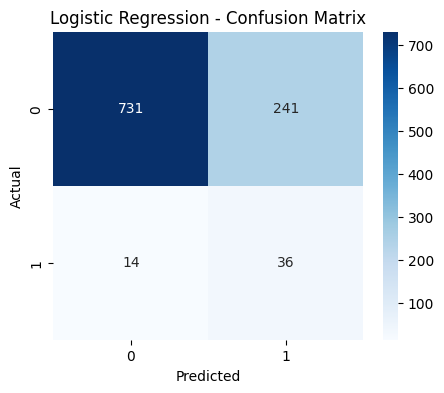

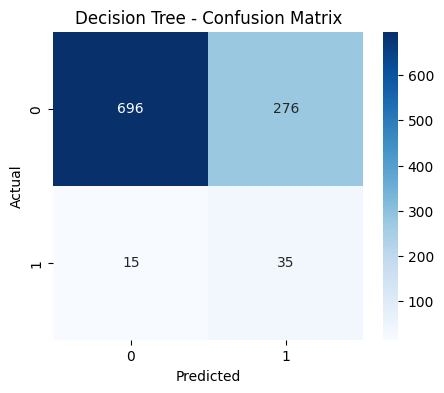

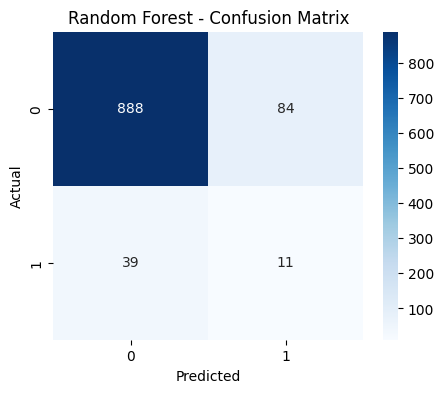

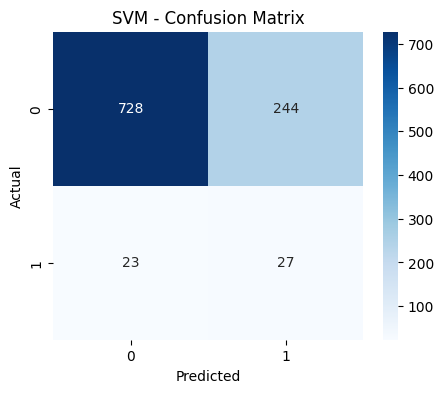

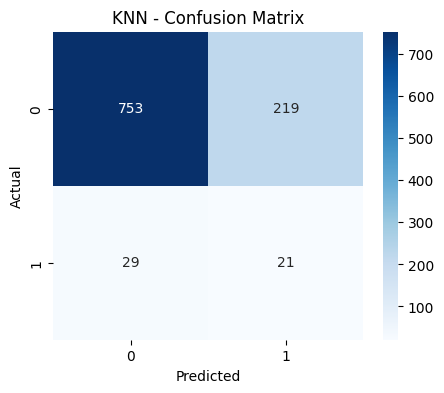

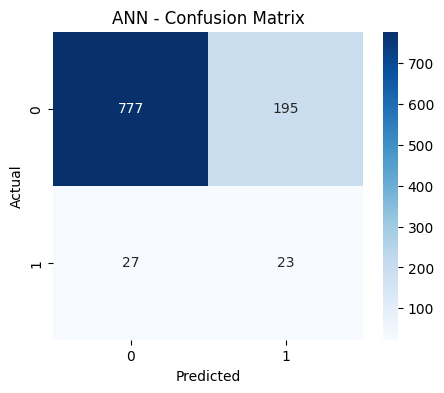

In [29]:
for name, pred in predictions.items():

    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

ROC Curve

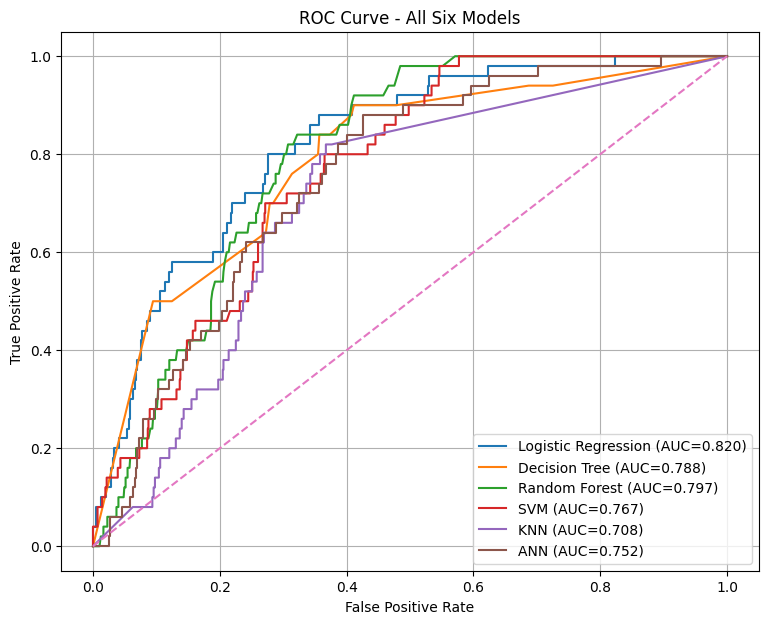

In [30]:
from sklearn.metrics import roc_curve, roc_auc_score

probabilities = {
    "Logistic Regression": lr_prob,
    "Decision Tree": dt_prob,
    "Random Forest": rf_prob,
    "SVM": svm_prob,
    "KNN": knn_prob,
    "ANN": ann_prob
}

plt.figure(figsize=(9, 7))

for name, prob in probabilities.items():

    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - All Six Models")

plt.legend()
plt.grid()

plt.show()

Top 3 Models

In [31]:
top3 = results_ranked.head(3)

print("Top 3 Models:")
display(top3)

Top 3 Models:


,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.129964,0.72,0.220183,0.750489,0.819979
1,Random Forest,0.115789,0.22,0.151724,0.879648,0.796605
2,Decision Tree,0.112540,0.70,0.193906,0.715264,0.787572


In [32]:
results_ranked = results_df.sort_values(
    by="AUC-ROC",
    ascending=False
).reset_index(drop=True)

display(results_ranked)

,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.129964,0.72,0.220183,0.750489,0.819979
1,Random Forest,0.115789,0.22,0.151724,0.879648,0.796605
2,Decision Tree,0.112540,0.70,0.193906,0.715264,0.787572
3,SVM,0.099631,0.54,0.168224,0.738748,0.766698
4,ANN,0.105505,0.46,0.171642,0.782779,0.752325
5,KNN,0.087500,0.42,0.144828,0.757339,0.707757


In [33]:
top3 = results_ranked.head(3)

display(top3)

,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.129964,0.72,0.220183,0.750489,0.819979
1,Random Forest,0.115789,0.22,0.151724,0.879648,0.796605
2,Decision Tree,0.112540,0.70,0.193906,0.715264,0.787572


Comparison Graph

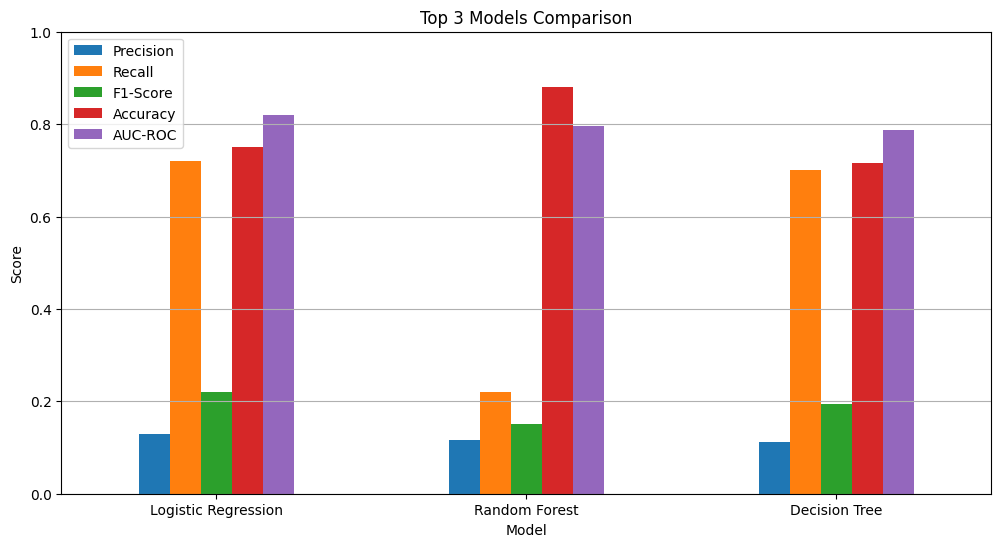

In [34]:
import matplotlib.pyplot as plt

top3_plot = top3.set_index("Model")[
    ["Precision", "Recall", "F1-Score", "Accuracy", "AUC-ROC"]
]

top3_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Top 3 Models Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

In [35]:
print("===== TOP 3 MODELS =====")
display(top3)

===== TOP 3 MODELS =====


,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.129964,0.72,0.220183,0.750489,0.819979
1,Random Forest,0.115789,0.22,0.151724,0.879648,0.796605
2,Decision Tree,0.112540,0.70,0.193906,0.715264,0.787572


Best model identify

In [36]:
best_model = results_ranked.iloc[0]

print("Best Model based on AUC-ROC:")
print(best_model)

Best Model based on AUC-ROC:
Model        Logistic Regression
Precision               0.129964
Recall                      0.72
F1-Score                0.220183
Accuracy                0.750489
AUC-ROC                 0.819979
Name: 0, dtype: object


In [39]:
print("========== FINAL CONCLUSION ==========")

print(
    f"The best performing model based on AUC-ROC is "
    f"{best_model['Model']}."
)

print(f"AUC-ROC   : {best_model['AUC-ROC']:.3f}")
print(f"Accuracy  : {best_model['Accuracy']:.3f}")
print(f"Precision : {best_model['Precision']:.3f}")
print(f"Recall    : {best_model['Recall']:.3f}")
print(f"F1-Score  : {best_model['F1-Score']:.3f}")

========== FINAL CONCLUSION ==========
The best performing model based on AUC-ROC is Logistic Regression.
AUC-ROC   : 0.820
Accuracy  : 0.750
Precision : 0.130
Recall    : 0.720
F1-Score  : 0.220
